# 02 - Baseline: TF-IDF + Logistic Regression
AG News, 4 classes: World, Sports, Business, Sci/Tech.
Notebook chạy từ thư mục `notebooks/`; logic nằm trong `src/baseline.py`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src import baseline

## 1. Train, chọn C trên validation, đánh giá trên test

In [2]:
metrics = baseline.run()

C=1.0   val macro-F1=0.9241  fit time=50.2s
C=5.0   val macro-F1=0.9232  fit time=30.2s
C=10.0  val macro-F1=0.9201  fit time=30.4s

=== Baseline (test set) ===
model                     baseline
accuracy                  0.918026
precision_macro           0.917902
recall_macro              0.918026
f1_macro                  0.917835
train_time_s             50.212524
inference_time_s          0.614437
inference_ms_per_sample   0.080847
trainable_params            200004
model_size_mb             3.408657

Confusion matrix (rows = true, cols = predicted):
[[1721   61   75   43]
 [  18 1862   10   10]
 [  56   19 1674  151]
 [  46   16  118 1720]]

              precision    recall  f1-score   support

       World     0.9348    0.9058    0.9201      1900
      Sports     0.9510    0.9800    0.9653      1900
    Business     0.8918    0.8811    0.8864      1900
    Sci/Tech     0.8940    0.9053    0.8996      1900

    accuracy                         0.9180      7600
   macro avg     0

## 2. Metrics đã lưu 

In [3]:
pd.read_csv(baseline.METRICS_PATH)

,model,accuracy,precision_macro,recall_macro,f1_macro,train_time_s,inference_time_s,inference_ms_per_sample,trainable_params,model_size_mb
0,baseline,0.918026,0.917902,0.918026,0.917835,50.212524,0.614437,0.080847,200004,3.408657


## 3. Confusion matrix

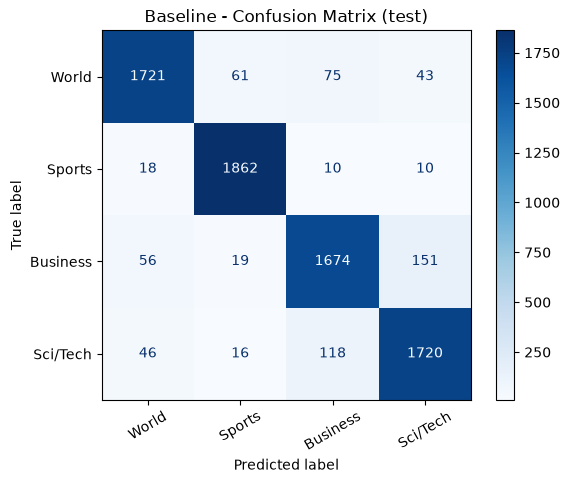

In [4]:
pred = pd.read_csv(baseline.PREDICTIONS_PATH)
cm = confusion_matrix(pred["true_label"], pred["pred_label"])
ConfusionMatrixDisplay(cm, display_labels=baseline.LABEL_NAMES).plot(cmap="Blues", xticks_rotation=30)
plt.title("Baseline - Confusion Matrix (test)")
plt.show()

## 4. Xem nhanh các mẫu dự đoán sai (tự tin cao nhất)

In [5]:
wrong = pred[pred["true_label"] != pred["pred_label"]].sort_values("confidence", ascending=False)
names = dict(enumerate(baseline.LABEL_NAMES))
wrong = wrong.assign(true_name=wrong["true_label"].map(names), pred_name=wrong["pred_label"].map(names))
print(f"Sai {len(wrong)} / {len(pred)} mẫu")
wrong[["text", "true_name", "pred_name", "confidence"]].head(10)

Sai 623 / 7600 mẫu


,text,true_name,pred_name,confidence
2591,Sports Court Hears Hamm Gold Medal Appeal LAUS...,World,Sports,0.993807
6592,"Sony, IBM, Toshiba Give Details of 'Cell' Chip...",Business,Sci/Tech,0.992323
5129,Product Previews palmOneUpgrades Treo With Fas...,Business,Sci/Tech,0.992066
5128,Argentina Basketball Coach Magnano Quits Ruben...,World,Sports,0.991133
1080,Davenport Advances at U.S. Open NEW YORK - Lin...,World,Sports,0.990632
747,Argentina Beats U.S. Men's Basketball Team Arg...,World,Sports,0.989937
1617,"At Last, Success on the Road for Lions The Det...",World,Sports,0.989887
4029,"USC, Miami Top BCS Standings, Not Okla. Southe...",World,Sports,0.989111
3617,Linux: Paris weighs a shift to open-source cam...,Business,Sci/Tech,0.987811
5740,Dow Jones Agrees to Buy MarketWatch in $519 Mi...,World,Business,0.985727
